# 2020 — Denoising Diffusion Probabilistic Models (DDPM)

**Papers:** Jonathan Ho, Ajay Jain & Pieter Abbeel, *"Denoising Diffusion Probabilistic Models"* (2020); building on Sohl-Dickstein et al. (2015) and Song & Ermon's score matching (2019).

- **Forward process:** gradually add Gaussian noise over $T$ steps until the data is pure noise. Any step can be sampled in closed form:
$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \qquad \epsilon\sim\mathcal N(0,I)$$
- **Training:** a network $\epsilon_\theta(x_t, t)$ predicts the noise. Loss: $\|\epsilon - \epsilon_\theta(x_t,t)\|^2$
- **Sampling:** start from noise and denoise step by step:
$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\Big) + \sigma_t z$$

Diffusion models replaced GANs for image, video and audio generation (DALL·E 2, Imagen, Stable Diffusion, Sora). We train a DDPM on 2-D data first (fast and easy to see), then on 8×8 digits.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
from sklearn.datasets import make_swiss_roll

PyTorch 2.15.0 | device: mps


In [2]:
T = 200
betas = torch.linspace(1e-4, 0.02 * 1000 / T, T, device=device)       # linear schedule (rescaled for T=200)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)

def q_sample(x0, t, eps):
    return abar[t].sqrt()[:, None] * x0 + (1 - abar[t]).sqrt()[:, None] * eps

class TimeEmbed(nn.Module):
    def __init__(self, d):
        super().__init__(); self.d = d
    def forward(self, t):
        f = torch.exp(-math.log(10000) * torch.arange(self.d // 2, device=t.device) / (self.d // 2))
        a = t[:, None].float() * f[None]
        return torch.cat([a.sin(), a.cos()], -1)

class EpsNet(nn.Module):
    def __init__(self, d_in, h=256):
        super().__init__()
        self.temb = nn.Sequential(TimeEmbed(64), nn.Linear(64, h), nn.SiLU())
        self.inp = nn.Linear(d_in, h)
        self.net = nn.Sequential(nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, d_in))
    def forward(self, x, t):
        return self.net(self.inp(x) + self.temb(t))

def train(model, data, steps, bs=256, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        x0 = data[torch.randint(0, len(data), (bs,), device=device)]
        t = torch.randint(0, T, (bs,), device=device); eps = torch.randn_like(x0)
        loss = F.mse_loss(model(q_sample(x0, t, eps), t), eps)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if s % (steps // 4) == 0: print(f"step {s:5d}  loss {loss.item():.4f}")

@torch.no_grad()
def sample(model, n, d, keep=()):
    x = torch.randn(n, d, device=device); traj = {}
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device)
        eps = model(x, tt)
        x = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0: x = x + betas[t].sqrt() * torch.randn_like(x)        # sigma_t^2 = beta_t
        if t in keep: traj[t] = x.cpu()
    return x, traj

## 2-D Swiss roll

step     0  loss 0.9709


step  1000  loss 0.3058


step  2000  loss 0.2471


step  3000  loss 0.2706


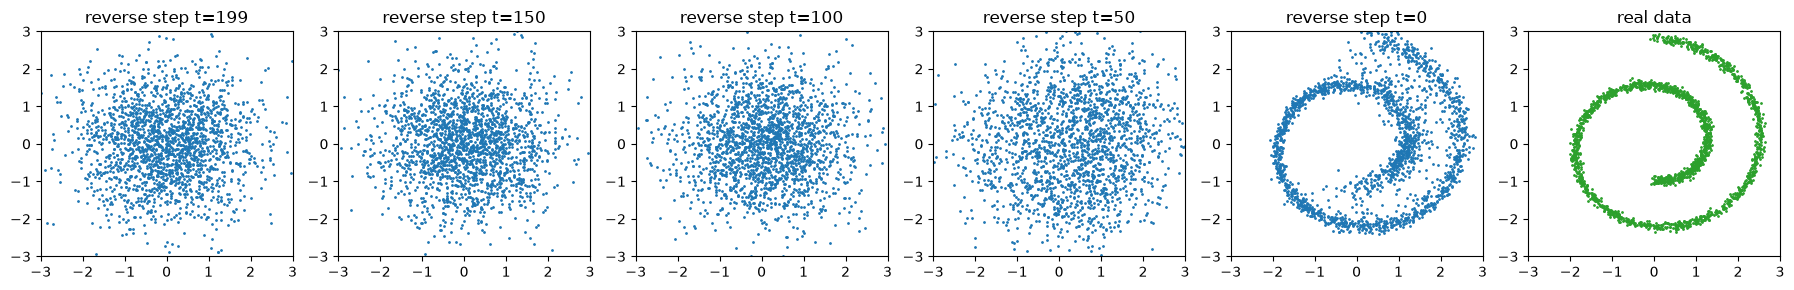

In [3]:
roll = torch.tensor(make_swiss_roll(10000, noise=0.3, random_state=0)[0][:, [0, 2]] / 5, dtype=torch.float32, device=device)
model2d = EpsNet(2).to(device)
train(model2d, roll, 4000)
_, traj = sample(model2d, 2000, 2, keep=(199, 150, 100, 50, 0))
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
x0 = roll[:2000].cpu()
for ax, t in zip(axes, [199, 150, 100, 50, 0]):
    ax.scatter(traj[t][:, 0], traj[t][:, 1], s=1); ax.set_title(f"reverse step t={t}"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
axes[5].scatter(x0[:, 0], x0[:, 1], s=1, c="C2"); axes[5].set_title("real data"); axes[5].set_xlim(-3, 3); axes[5].set_ylim(-3, 3)
plt.tight_layout(); plt.show()

## Forward process on data

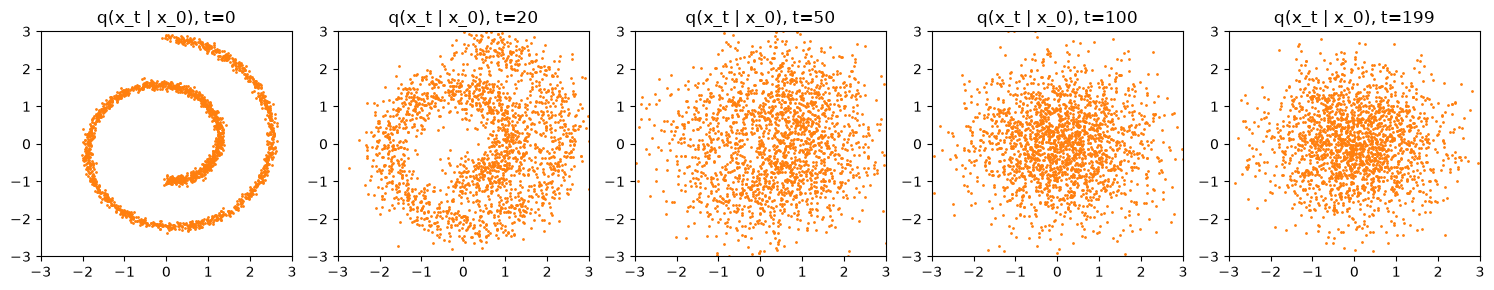

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, t in zip(axes, [0, 20, 50, 100, 199]):
    xt = q_sample(roll[:2000], torch.full((2000,), t, device=device), torch.randn_like(roll[:2000])).cpu()
    ax.scatter(xt[:, 0], xt[:, 1], s=1, c="C1"); ax.set_title(f"q(x_t | x_0), t={t}"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

## 8×8 handwritten digits
The same algorithm with a bigger MLP. (Real image models use a U-Net or a Transformer as the denoiser.)

step     0  loss 0.9952


step  2000  loss 0.1372


step  4000  loss 0.1288


step  6000  loss 0.1329


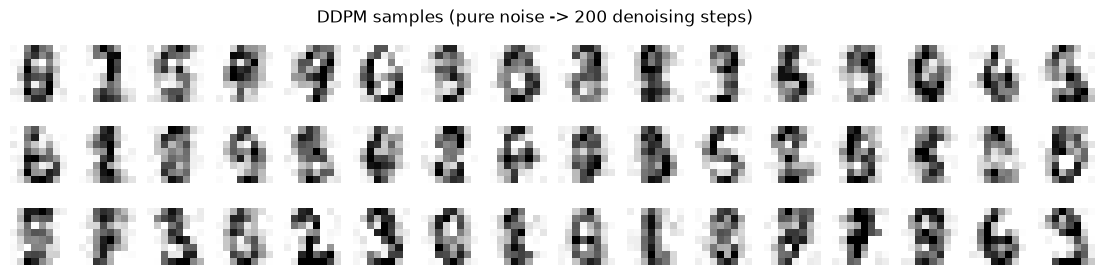

In [5]:
from sklearn.datasets import load_digits
digits = torch.tensor(load_digits().data / 16.0 * 2 - 1, dtype=torch.float32, device=device)   # scale to [-1, 1]
model_dg = EpsNet(64, h=512).to(device)
train(model_dg, digits, 8000, lr=5e-4)
gen, _ = sample(model_dg, 48, 64)
fig, axes = plt.subplots(3, 16, figsize=(14, 3))
for ax, g in zip(axes.flat, gen.clamp(-1, 1).cpu()): ax.imshow(g.view(8, 8), cmap="gray_r"); ax.axis("off")
plt.suptitle("DDPM samples (pure noise -> 200 denoising steps)"); plt.show()